# Credit Portfolio Risk & Economic Capital

This notebook reproduces the credit portfolio model used in this project step by step.

**Objective:** simulate portfolio losses, calculate EL / VaR / Expected Shortfall, estimate economic capital and compare it with Basel II IRB-style regulatory capital.

The inputs are synthetic and come from an MSc academic exercise. The model was reimplemented in Python to make the analysis reproducible and easier to extend.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.model import load_inputs, simulate_credit_losses
from src.metrics import analytical_expected_loss, portfolio_metrics, es_contributions
from src.irb import calculate_irb_capital

## 1. Portfolio inputs

The portfolio combines three granular retail books and two large single-name corporate exposures. The three key credit parameters are:

- **PD**: Probability of Default
- **LGD**: Loss Given Default
- **EAD**: Exposure at Default

In [2]:
portfolio, corr = load_inputs(ROOT / "data")
portfolio

,position,type,ead_mn,pd,lgd,rho_economic,regulatory_class
0,C1,Retail,100,0.0100,0.55,0.20,other_retail
1,C2,Retail,150,0.0150,0.55,0.04,qrre
2,C3,Retail,180,0.0120,0.30,0.15,residential_mortgage
3,E1,Corporate,45,0.0038,0.45,NaN,corporate
4,E2,Corporate,180,0.0090,0.35,NaN,corporate


In [3]:
pd.DataFrame(corr, index=["FS1", "FS2", "FS3"], columns=["FS1", "FS2", "FS3"])

,FS1,FS2,FS3
FS1,1.0,0.8,0.7
FS2,0.8,1.0,0.6
FS3,0.7,0.6,1.0


## 2. Analytical Expected Loss

Before simulating anything, the portfolio mean loss can be checked analytically with:

`EL = Σ(PD × LGD × EAD)`

Dependence between borrowers changes the volatility and the tail of the portfolio, but not this simple marginal expected-loss calculation.

In [4]:
analytical_el = analytical_expected_loss(portfolio)
print(f"Analytical Expected Loss: {analytical_el:.4f} M€")

Analytical Expected Loss: 3.0795 M€


## 3. Monte Carlo simulation

We generate correlated sector factors with a Cholesky decomposition. Retail portfolio losses follow conditional Vasicek/ASRF default rates, while the two corporate exposures retain idiosyncratic single-name default risk.

For notebook speed we use 250,000 scenarios. `run_analysis.py` defaults to 1,000,000 scenarios.

In [5]:
losses, diagnostics = simulate_credit_losses(
    n_scenarios=250_000,
    seed=42,
    data_dir=ROOT / "data",
)
metrics = portfolio_metrics(losses)
metrics

{'n_scenarios': 250000,
 'expected_loss': 3.089728703849103,
 'std_loss': 7.180144600145959,
 'var': 79.37154701144367,
 'expected_shortfall': 94.9306224417275,
 'economic_capital_var_minus_el': 76.28181830759456,
 'economic_capital_es_minus_el': 91.84089373787839,
 'confidence': 0.999}

In [6]:
print(f"Simulated E1 default rate: {diagnostics['simulated_default_rate_E1']:.4%}")
print(f"Target E1 PD:              {portfolio.loc[portfolio.position=='E1','pd'].iloc[0]:.4%}")
print(f"Simulated E2 default rate: {diagnostics['simulated_default_rate_E2']:.4%}")
print(f"Target E2 PD:              {portfolio.loc[portfolio.position=='E2','pd'].iloc[0]:.4%}")

Simulated E1 default rate: 0.3996%
Target E1 PD:              0.3800%
Simulated E2 default rate: 0.9004%
Target E2 PD:              0.9000%


## 4. Loss distribution and tail risk

- **VaR 99.9%** is the loss threshold exceeded in roughly 0.1% of scenarios.
- **Expected Shortfall 99.9%** is the average loss once the portfolio is already in that extreme tail.
- **Economic Capital** in this exercise is defined as `VaR - Expected Loss`.

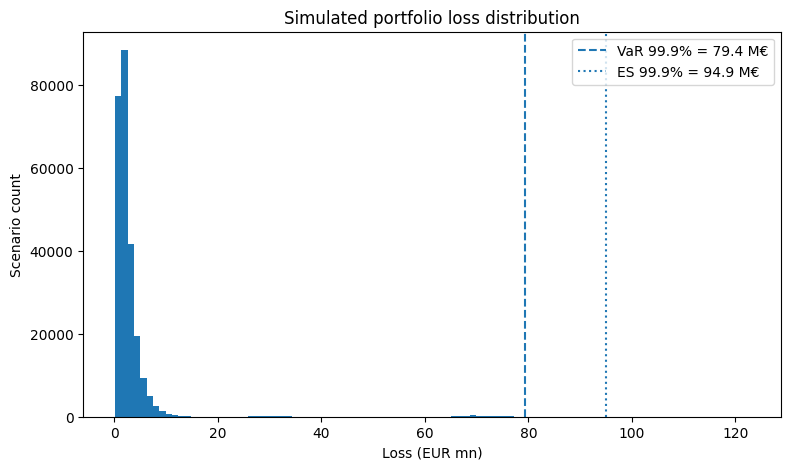

In [7]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(losses["Total"], bins=100)
ax.axvline(metrics["var"], linestyle="--", label=f"VaR 99.9% = {metrics['var']:.1f} M€")
ax.axvline(metrics["expected_shortfall"], linestyle=":", label=f"ES 99.9% = {metrics['expected_shortfall']:.1f} M€")
ax.set_title("Simulated portfolio loss distribution")
ax.set_xlabel("Loss (EUR mn)")
ax.set_ylabel("Scenario count")
ax.legend();

## 5. Which positions drive the tail?

Expected Shortfall contribution is calculated as each position's average loss in the same portfolio-tail scenarios. This shows which exposures actually dominate severe losses.

In [8]:
contrib = es_contributions(losses)
contrib.style.format({"es_contribution_mn":"{:.3f}", "share_of_es":"{:.1%}"})

,es_contribution_mn,share_of_es
C1,7.049,7.4%
C2,4.031,4.2%
C3,5.866,6.2%
E1,14.985,15.8%
E2,63.000,66.4%


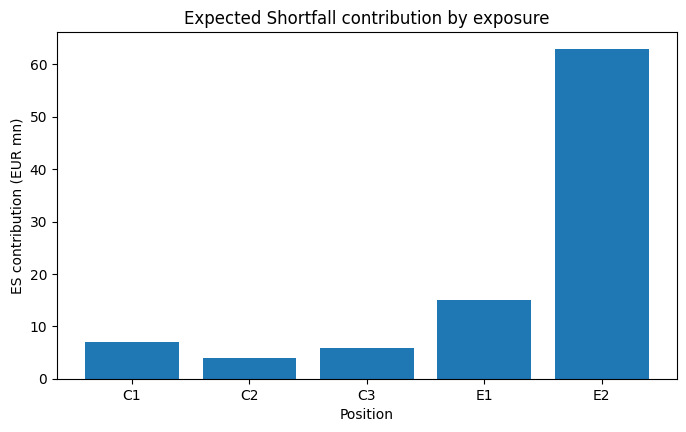

In [9]:
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(contrib.index, contrib["es_contribution_mn"])
ax.set_title("Expected Shortfall contribution by exposure")
ax.set_xlabel("Position")
ax.set_ylabel("ES contribution (EUR mn)");

## 6. Basel II IRB-style regulatory capital

The coursework also calculates regulatory capital using exposure-specific regulatory correlations and the ASRF/IRB-style 99.9% formula. RWA is obtained as `12.5 × capital`.

In [10]:
irb = calculate_irb_capital(portfolio)
irb[["position", "regulatory_class", "regulatory_correlation", "capital_mn", "rwa_mn"]].style.format({
    "regulatory_correlation":"{:.2%}",
    "capital_mn":"{:.3f}",
    "rwa_mn":"{:.2f}",
})

,position,regulatory_class,regulatory_correlation,capital_mn,rwa_mn
0,C1,other_retail,12.16%,4.476,55.94
1,C2,qrre,4.00%,3.431,42.89
2,C3,residential_mortgage,15.00%,6.105,76.32
3,E1,corporate,21.92%,1.609,20.11
4,E2,corporate,19.65%,7.832,97.90


In [11]:
reg_capital = irb["capital_mn"].sum()
econ_capital = metrics["economic_capital_var_minus_el"]
comparison = pd.DataFrame({
    "Capital (M€)": [econ_capital, reg_capital]
}, index=["Economic capital (VaR - EL)", "Regulatory capital (IRB)"])
comparison

,Capital (M€)
Economic capital (VaR - EL),76.281818
Regulatory capital (IRB),23.453659


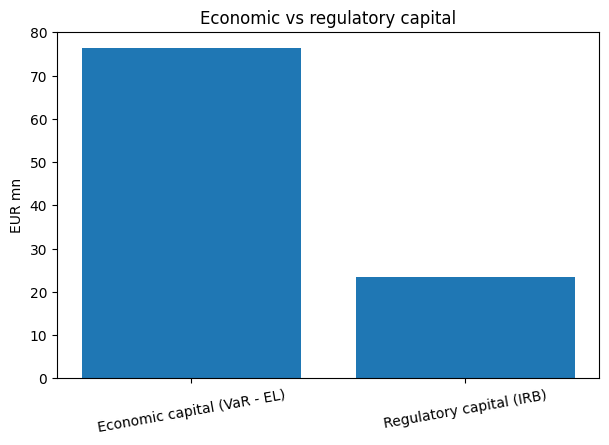

In [12]:
fig, ax = plt.subplots(figsize=(7,4.5))
ax.bar(comparison.index, comparison["Capital (M€)"])
ax.set_ylabel("EUR mn")
ax.set_title("Economic vs regulatory capital")
ax.tick_params(axis='x', rotation=10);

## 7. Interpretation

The key result is the **structure of the tail**, rather than the exact Monte Carlo decimal.

The two corporate exposures, particularly E2, dominate severe-loss scenarios. The economic model retains this single-name idiosyncratic risk, while the IRB/ASRF framework is based on an asymptotic granularity assumption. This explains why economic capital can be much higher than Pillar 1 regulatory capital in a concentrated portfolio.

The exercise also shows that portfolios with similar Expected Loss can still have very different tail risk when concentration and dependence change.


## 8. Scope

This is a portfolio loss and capital model. It does not develop borrower scoring/rating models, estimate PD/LGD from real client data, or implement IFRS 9 staging or lifetime ECL.
